# Smartphone Specs Analysis
**Problem statement.** Smartphones range from budget handsets to premium foldables. Using specifications scraped from GSMArena, this project cleans the data, reduces it with PCA, finds market segments with K-Means and hierarchical clustering, and tests how well the specs predict price with linear regression.

**Data source.** GSMArena (`gsmarena.com`), scraped with `requests` + `BeautifulSoup` (`scraper/scrape_gsmarena.py`), 5–9 s delay between requests on **21–22 November 2026**. The newest ~60 devices across 16 brands were collected (**938 raw rows**); after removing non-phones, pre-2018 models, and rows without a EUR price, **657 smartphones** remain (one row per phone, base memory variant).

In [1]:
# [C1] Setup
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer, SimpleImputer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42
os.makedirs("../figures", exist_ok=True)

def save(name):
    """Save the current plot to ../figures for the report. Call it just before plt.show()."""
    plt.savefig(f"../figures/{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the raw data
First we load the file the scraper produced and check it before touching it: size, duplicates, objects that are not phones, impossible values, and how many phones each brand contributed.

In [2]:
# [C2] Load and health check
df = pd.read_csv("../data/gsmarena_phones_raw.csv")
print("raw shape:", df.shape)
print("scraping dates:", list(df["scraped_on"].unique()))
print("duplicates:", df.duplicated(subset="url").sum())
print("watches:", df["name"].str.contains(r"\bwatch", case=False).sum())
print("refresh_hz above 240 (should be 0):", (df["refresh_hz"] > 240).sum())
print("\nphones per brand:"); print(df["brand"].value_counts().to_string())
print("\ncurrency of the listed price:"); print(df["price_currency"].value_counts(dropna=False))

raw shape: (938, 29)
scraping dates: ['2026-11-21', '2026-11-22']
duplicates: 0
watches: 3
refresh_hz above 240 (should be 0): 0

phones per brand:
brand
Samsung     63
Xiaomi      60
Oppo        60
Vivo        60
OnePlus     60
Realme      60
Motorola    60
Nokia       60
Infinix     60
Tecno       60
Honor       60
Huawei      60
Sony        60
Asus        60
Apple       56
Google      39

currency of the listed price:
price_currency
EUR    581
INR    143
USD    111
NaN     77
GBP     26
Name: count, dtype: int64


## 2. Cleaning: keep modern smartphones only
Four filters, each with a reason:
* **Duplicates** are removed using the page URL.
* **Watches** are not phones, so they are removed.
* **Year ≥ 2018:** older phones come from a different specification era (RAM in MB, no fast charging) and would distort PCA and clustering.
* **Feature phones** (no operating system listed, or KaiOS) are a different product class: no app store, memory listed in MB, so RAM and storage are missing for all of them.
* **Tablets** (MatePad, MagicPad, Xpad, Megapad, Nokia T-series) were found when checking the outliers: 11-14 inch screens and 450-790 g weights. They are a different product class, so they are removed too.

The table below shows how many rows each step removes.

In [3]:
# [C3] Cleaning funnel
n0 = len(df)
df = df.drop_duplicates(subset="url");                                  n1 = len(df)
df = df[~df["name"].str.contains(r"\bwatch", case=False, regex=True)];  n2 = len(df)
df = df[df["year"] >= 2018];                                            n3 = len(df)

is_feature = df["os"].isna() | df["os"].str.contains("KaiOS", na=False)
df = df[~is_feature];                                                   n4 = len(df)

# tablets: names containing "pad" (MatePad, MagicPad, Xpad, Megapad, iPad ...) + Nokia T-series tablets
is_tablet = df["name"].str.contains("pad", case=False) | \
            ((df["brand"] == "Nokia") & df["name"].isin(["T10", "T20", "T21"]))
tablets = df.loc[is_tablet, ["brand", "name"]]
df = df[~is_tablet].reset_index(drop=True);                             n5 = len(df)

print(pd.Series({"raw": n0, "no duplicates": n1, "no watches": n2, "year >= 2018": n3,
                 "no feature phones": n4, "no tablets": n5}))
print("\ntablets removed:", len(tablets))
print(tablets.to_string(index=False))

raw                  938
no duplicates        938
no watches           935
year >= 2018         871
no feature phones    835
no tablets           802
dtype: int64

tablets removed: 33
  brand                  name
   Vivo            IQOO Pad5c
   Vivo         iQOO Pad6 Pro
   Vivo              Pad6 Pro
  Nokia                   T21
  Nokia                   T10
Infinix           Xpad 30 Pro
Infinix              Xpad 30E
Infinix             Xpad Edge
Infinix           Xpad 20 Pro
Infinix               Xpad 20
Infinix               Xpad GT
Infinix                  Xpad
  Tecno             Megapad 2
  Tecno            Megapad SE
  Tecno           Megapad Pro
  Tecno            Megapad 11
  Tecno               Megapad
  Honor       MagicPad 4 12.1
  Honor   MagicPad 3 Pro 12.3
  Honor             MagicPad4
  Honor    MagicPad3 Pro 13.3
 Huawei   MatePad Air Z Enjoy
 Huawei         MatePad Air Z
 Huawei MatePad Pro 12 (2026)
 Huawei    MatePad Air (2026)
 Huawei       MatePad Pro Max
 Huawe

## 3. Target variable: the price in EUR
GSMArena lists the price in different currencies depending on the phone, and sometimes several at once. These numbers are **not simple conversions of each other**: for phones that list both a USD and a EUR figure, the ratio USD/EUR varies a lot (see below), because they come from different markets and memory versions.

We therefore use the **EUR price that GSMArena lists** as the target. This avoids guessed exchange rates and keeps one consistent source. Out of **802** filtered modern smartphones, **657** list a EUR price and are retained. Among the **166** phones listing both USD and EUR figures, the `USD / EUR` ratio spans **0.47 to 6.87** (**median 1.01**, **IQR 0.89–1.26**), confirming that multi-currency listings come from different regional markets and storage tiers rather than fixed exchange-rate conversions.

**Limitation:** The prices are European-market estimates ("About X EUR"), rounded, and for older models can reflect used-market prices.

In [4]:
# [C4] Target: the EUR price GSMArena lists (no exchange rates anywhere)
SYMBOL = {"€": "EUR", "£": "GBP", "₹": "INR", "$": "USD"}
PAT = re.compile(r"(€|£|₹|\$)\s*([\d,]+(?:\.\d+)?)|([\d,]+(?:\.\d+)?)\s*(EUR|GBP|INR|USD)")

def parse_prices(raw):
    """Return {currency: first number listed} from text like '$ 799 / € 899'."""
    found = {}
    if isinstance(raw, str):
        for m in PAT.finditer(raw):
            cur, val = (SYMBOL[m.group(1)], m.group(2)) if m.group(1) else (m.group(4), m.group(3))
            found.setdefault(cur, float(val.replace(",", "")))
    return found

listed = df["price_raw"].apply(parse_prices)
df["price"] = listed.apply(lambda d: d.get("EUR"))
print("smartphones with a EUR price:", df["price"].notna().sum(), "of", len(df))

# Evidence: prices in other currencies are not conversions of the EUR one
both = listed.apply(lambda d: "USD" in d and "EUR" in d)
ratio = listed[both].apply(lambda d: d["USD"] / d["EUR"])
print("\nUSD number / EUR number for phones listing both (about 1.1-1.2 if they were conversions):")
print(ratio.describe().round(2))

smartphones with a EUR price: 657 of 802

USD number / EUR number for phones listing both (about 1.1-1.2 if they were conversions):
count    166.00
mean       1.21
std        0.75
min        0.47
25%        0.89
50%        1.01
75%        1.26
max        6.87
Name: price_raw, dtype: float64


8 cheapest:
            name    brand  year     price_raw  price
509         C100    Nokia  2022  About 50 EUR   50.0
492         C300    Nokia  2023  About 60 EUR   60.0
503         G100    Nokia  2022  About 60 EUR   60.0
508         C200    Nokia  2022  About 60 EUR   60.0
526  Smart 10 HD  Infinix  2025  About 60 EUR   60.0
528     Smart 10  Infinix  2025  About 60 EUR   60.0
550  Note 40 Pro  Infinix  2024  About 60 EUR   60.0
506         G400    Nokia  2022  About 70 EUR   70.0

8 most expensive:
                   name   brand  year                        price_raw   price
763         ROG Phone 8    Asus  2024                   About 3260 EUR  3260.0
762     ROG Phone 8 Pro    Asus  2024                   About 2600 EUR  2600.0
683  Mate XT 2 Ultimate  Huawei  2026  About 2570 EUR (price in China)  2570.0
57           iPhone Duo   Apple  2026          £ 1,999.00 / € 2,299.00  2299.0
717   Mate XTs Ultimate  Huawei  2025  About 2160 EUR (price in China)  2160.0
764          Zenfo

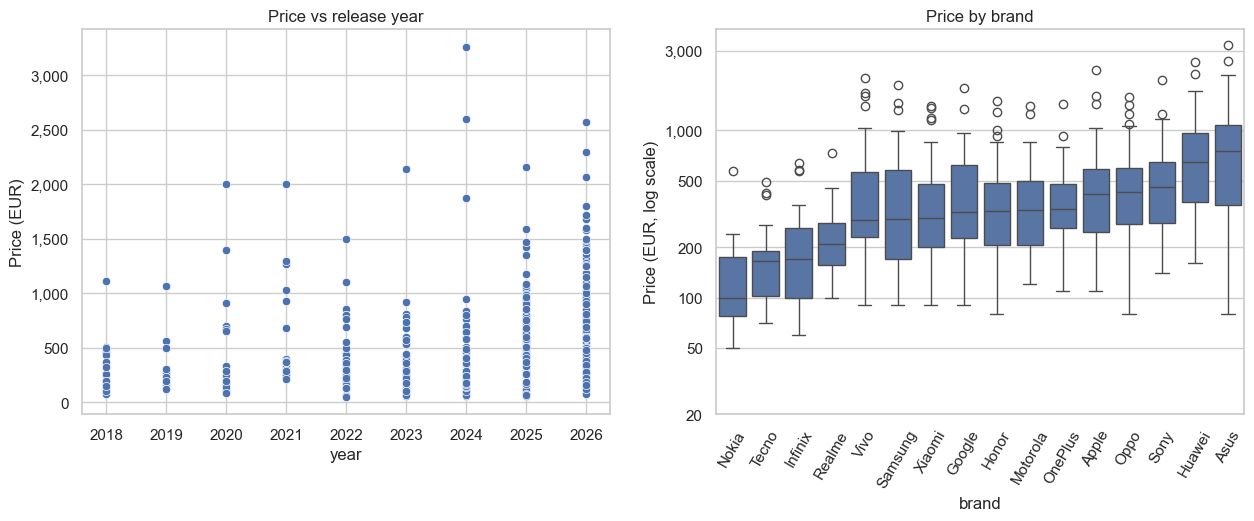

In [5]:
# [C5] Look at the price column
cols = ["name", "brand", "year", "price_raw", "price"]
print("8 cheapest:");        print(df.nsmallest(8, "price")[cols].to_string())
print("\n8 most expensive:"); print(df.nlargest(8, "price")[cols].to_string())
print("\nmedian price (EUR) by brand:")
print(df.groupby("brand")["price"].median().sort_values().round(0).to_string())

fmt = FuncFormatter(lambda x, _: f"{x:,.0f}")
order = df.groupby("brand")["price"].median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="year", y="price", ax=ax[0])
ax[0].yaxis.set_major_formatter(fmt); ax[0].set_ylabel("Price (EUR)"); ax[0].set_title("Price vs release year")
sns.boxplot(data=df, x="brand", y="price", order=order, ax=ax[1])
ax[1].set_yscale("log"); ax[1].set_yticks([20, 50, 100, 200, 500, 1000, 3000])
ax[1].yaxis.set_major_formatter(fmt); ax[1].yaxis.set_minor_formatter(NullFormatter())
ax[1].tick_params(axis="x", rotation=60)
ax[1].set_ylabel("Price (EUR, log scale)"); ax[1].set_title("Price by brand")
save("price_overview"); plt.show()

## 4. (a) Feature engineering: missing values
We define the columns used later, then measure how much is missing in each. The 40% rule: a column with more than 40% missing would be dropped as too sparse to impute reliably.
* `FEATURES`: continuous specs, used for PCA and clustering. Price is kept out on purpose (it is the regression target).
* `BINARY`: yes/no specs, used only in the regression.

C:\Users\NISCHAL SHARMA\AppData\Local\Temp\ipykernel_2888\77683891.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_pro_ultra"] = df["name"].str.contains(r"\b(pro|ultra|max|ultimate|rs)\b", case=False, na=False).astype(int)


rows: 802
              missing  percent
price             145     18.1
refresh_hz         91     11.3
weight_g           35      4.4
charging_w         25      3.1
selfie_mp           6      0.7
thickness_mm        5      0.6
storage_gb          1      0.1
main_cam_mp         1      0.1
ram_gb              1      0.1
n_rear_cams         1      0.1
screen_in           0      0.0
ppi                 0      0.0
battery_mah         0      0.0


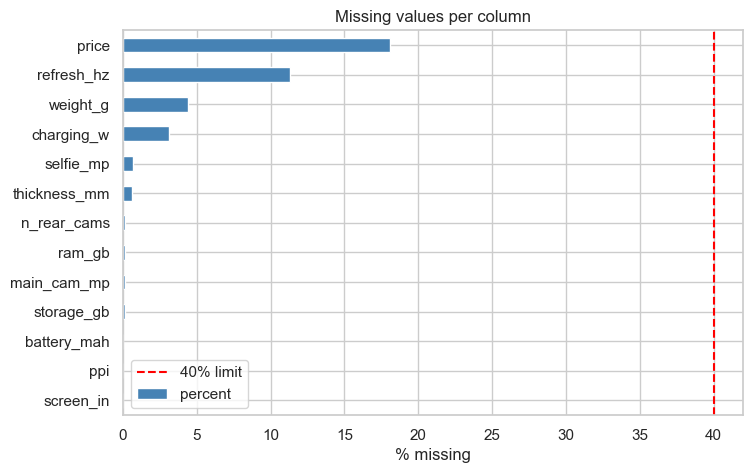

In [6]:
# [C6] Feature extraction from text + Columns and missing-value table
# 1. Form factor & model tier from 'name'
df["is_foldable"] = df["name"].str.contains(r"fold|flip|trifold|duo", case=False, na=False).astype(int)
df["is_pro_ultra"] = df["name"].str.contains(r"\b(pro|ultra|max|ultimate|rs)\b", case=False, na=False).astype(int)

# 2. Chipset tier & lithography (nm) from 'chipset'
df["is_flagship_chip"] = df["chipset"].str.contains(
    r"Snapdragon 8|Dimensity 9|Apple A1[4-9]|Apple A20|Tensor G[3-6]|Kirin 90[1-5]|Exynos 2[4-6]",
    case=False, na=False
).astype(int)

nm_extracted = df["chipset"].str.extract(r"(\d+)\s*nm", expand=False).astype(float)
df["chip_nm"] = df["chipset"].str.extract(r"(\d+)\s*nm", expand=False).astype(float)

# 3. Market availability from 'status'
df["is_discontinued"] = df["status"].str.contains("Discontinued", case=False, na=False).astype(int)

FEATURES = ["screen_in", "weight_g", "thickness_mm", "ppi", "refresh_hz", "ram_gb", "storage_gb",
            "main_cam_mp", "selfie_mp", "n_rear_cams", "battery_mah", "charging_w"]

BINARY = ["has_5g", "has_nfc", "is_oled", "has_card_slot",
          "is_foldable", "is_pro_ultra", "is_flagship_chip", "is_discontinued"]

miss = df[FEATURES + ["price"]].isna().sum().to_frame("missing")
miss["percent"] = (miss["missing"] / len(df) * 100).round(1)
print("rows:", len(df))
print(miss.sort_values("missing", ascending=False))

fig, ax = plt.subplots(figsize=(8, 5))
miss["percent"].sort_values().plot.barh(ax=ax, color="steelblue")
ax.axvline(40, color="red", ls="--", label="40% limit"); ax.legend()
ax.set_xlabel("% missing"); ax.set_title("Missing values per column")
save("missing_values"); plt.show()


### `refresh_hz`: a blank means 60 Hz
GSMArena only prints the refresh rate when it is above 60 Hz. Check on our data: **none** of the stated values is 60, and the blanks are the iPhones 11-16 (non-Pro) and budget Galaxy phones, which have standard 60 Hz screens. So the blanks are filled with **60**, not with a mean/median/KNN estimate that could invent a high refresh rate. The column `refresh_stated` remembers which rows were filled.

In [7]:
# [C7] refresh_hz rule
print("refresh rates GSMArena states:", sorted(df["refresh_hz"].dropna().astype(int).unique().tolist()))
print("stated values equal to 60:", (df["refresh_hz"] == 60).sum())
print("blank refresh_hz (filled with 60):", df["refresh_hz"].isna().sum())

if "refresh_stated" not in df:                       # makes the cell safe to re-run
    df["refresh_stated"] = df["refresh_hz"].notna().astype(int)
df["refresh_hz"] = df["refresh_hz"].fillna(60)

refresh rates GSMArena states: [90, 120, 144, 165, 185]
stated values equal to 60: 0
blank refresh_hz (filled with 60): 91


### The target is never imputed
Rows without a EUR price are dropped. Filling in the target would mean training the regression on invented labels. The remaining gaps in the features are listed afterwards.

In [8]:
# [C8] Drop rows without a price, then list the remaining feature gaps
print("rows without a EUR price (dropped):", df["price"].isna().sum())
df = df.dropna(subset=["price"]).reset_index(drop=True)

print("rows left:", len(df))
print(df["price"].describe().round(0))
print("\nfeature gaps still to handle:")
print(df[FEATURES].isna().sum()[lambda s: s > 0])

rows without a EUR price (dropped): 145
rows left: 657
count     657.0
mean      446.0
std       401.0
min        50.0
25%       190.0
50%       311.0
75%       570.0
max      3260.0
Name: price, dtype: float64

feature gaps still to handle:
weight_g        20
thickness_mm     4
selfie_mp        5
charging_w      20
dtype: int64


### Why are the remaining values missing?
Before choosing an imputation method we look at which phones have the gaps. If they follow a pattern (e.g. all one brand, all foldables), that points to how the data was collected or to a limitation of the scraper, and changes what we do about them.

In [9]:
# [C9] Which phones have the remaining gaps?
for c in df[FEATURES].columns[df[FEATURES].isna().any()]:
    print(f"\n{c}: {df[c].isna().sum()} missing")
    print(df.loc[df[c].isna(), ["name", "brand", "year"]].head(12).to_string())


weight_g: 20 missing
               name     brand  year
341  Moto G17 Power  Motorola  2026
345        Moto G57  Motorola  2025
404        C12 Plus     Nokia  2023
417            C100     Nokia  2022
418       Smart 20e   Infinix  2026
419     Smart 20 HD   Infinix  2026
458       Spark 50c     Tecno  2026
460  Spark Go 3 Pro     Tecno  2026
462        Pop X 4G     Tecno  2026
464      Spark Go 3     Tecno  2026
468       Spark 40C     Tecno  2025
472    Spark 40 Pro     Tecno  2025

thickness_mm: 4 missing
               name     brand  year
345        Moto G57  Motorola  2025
404        C12 Plus     Nokia  2023
460  Spark Go 3 Pro     Tecno  2026
482       Spark 30C     Tecno  2024

selfie_mp: 5 missing
                  name   brand  year
322          Narzo 80x  Realme  2025
634     Zenfone 8 Flip    Asus  2021
639      Zenfone 7 Pro    Asus  2020
640          Zenfone 7    Asus  2020
644  Zenfone 6 ZS630KL    Asus  2019

charging_w: 20 missing
                  name     brand  yea

### What the missing values turned out to be
We checked the GSMArena pages of several affected phones by hand. Missing weights (e.g. Moto G17 Power, C12 Plus) show "-" on the site, and missing charging (Moto G57, C12 Plus) show "No charging section stated"; the iPhone 11 family lists charging without any wattage. So the gaps are **in the source, not scraper errors**, and they concentrate in budget phones. We therefore impute them, using a method chosen by testing on our own data.

Also noted: some prices are GSMArena estimates that look high or low compared with typical retail prices (e.g. ROG Phone 8 at 3260 EUR); the parsing is correct, so this is noise in the source.

### Choosing an imputation method
We compare three methods by an experiment: take phones with **all** specs present, hide 10% of the values at random, let each method guess them, and measure how far the guesses are from the true values. This is repeated 20 times with different random masks.
* **Mean / median:** one value per column for every phone.
* **KNN (k = 5):** fills each gap with the average of the 5 most similar phones.

Specs are **standardised first** (mean 0, std 1), otherwise battery (thousands of mAh) would dominate the distance between phones over screen size (inches). The error is also measured in standard deviations, so every column counts equally.

phones with every spec present: 615 of 657

error in std-devs (lower is better), over 20 random masks:
         mean    std
method              
knn     0.603  0.020
mean    1.006  0.030
median  1.034  0.037


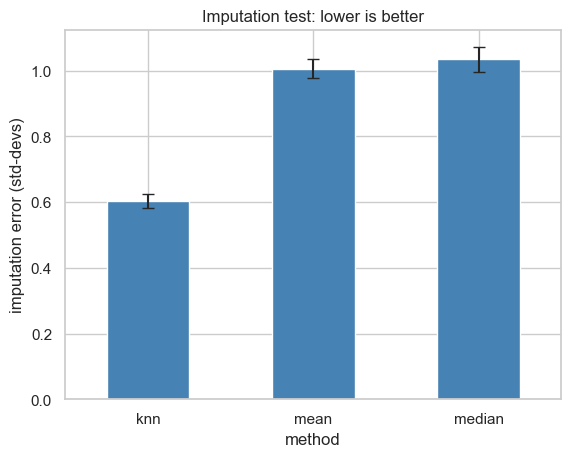

In [10]:
# [C10] Imputation experiment: mean vs median vs KNN
def impute_scaled(X, method):
    sc = StandardScaler().fit(X)                  # standardise (NaN are ignored when fitting)
    Z = sc.transform(X)
    if method == "knn":
        Z2 = KNNImputer(n_neighbors=5).fit_transform(Z)
    else:
        Z2 = SimpleImputer(strategy=method).fit_transform(Z)
    return sc.inverse_transform(Z2)               # back to real units

complete = df[FEATURES].dropna()
print("phones with every spec present:", len(complete), "of", len(df))
Xc = complete.values.astype(float)
sd = Xc.std(axis=0)
rng = np.random.default_rng(RANDOM_STATE)

rows = []
for rep in range(20):
    mask = rng.random(Xc.shape) < 0.10            # hide 10% of the values
    Xm = Xc.copy(); Xm[mask] = np.nan
    for m in ["mean", "median", "knn"]:
        Xi = impute_scaled(Xm, m)
        rows.append({"method": m, "error": np.sqrt((((Xi - Xc) / sd)[mask] ** 2).mean())})

res = pd.DataFrame(rows).groupby("method")["error"].agg(["mean", "std"]).round(3)
print("\nerror in std-devs (lower is better), over 20 random masks:")
print(res)

res["mean"].plot.bar(yerr=res["std"], rot=0, capsize=4, color="steelblue")
plt.ylabel("imputation error (std-devs)"); plt.title("Imputation test: lower is better")
save("imputation_test"); plt.show()

In [11]:
# [C11] Apply the best method to the real gaps
best = res["mean"].idxmin()
gaps = df[FEATURES].isna()
print("method chosen:", best, "| missing values before:", int(gaps.sum().sum()))

df_unimputed = df.copy()        # save a copy of the dataframe before imputation
df[FEATURES] = impute_scaled(df[FEATURES].values.astype(float), best)
df["n_rear_cams"] = df["n_rear_cams"].round()
print("missing values after:", int(df[FEATURES].isna().sum().sum()))

print("\nexample imputed weights:")
print(df.loc[gaps["weight_g"], ["name", "brand", "weight_g"]].head(8).round(0).to_string())

method chosen: knn | missing values before: 49
missing values after: 0

example imputed weights:
               name     brand  weight_g
341  Moto G17 Power  Motorola     206.0
345        Moto G57  Motorola     185.0
404        C12 Plus     Nokia     179.0
417            C100     Nokia     159.0
418       Smart 20e   Infinix     195.0
419     Smart 20 HD   Infinix     195.0
458       Spark 50c     Tecno     200.0
460  Spark Go 3 Pro     Tecno     195.0


## 4. (a) Feature engineering: outliers
Two detection methods are compared:
* **IQR rule:** a value is an outlier if it lies below Q1 - 1.5 IQR or above Q3 + 1.5 IQR. It makes no assumption about the distribution, so it suits skewed columns.
* **Z-score rule:** a value is an outlier if |z| > 3. It assumes a roughly symmetric distribution, so for **right-skewed** columns (skew > 1) it is computed on log(1 + x) instead of the raw values.

The table below counts how many phones each method flags per column, and how many are flagged by **both**.

In [12]:
# [C12] Outlier detection: IQR and Z-score
OUT_COLS = FEATURES + ["price"]

def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

flags, rows = {}, []
for c in OUT_COLS:
    s = df[c]
    lo, hi = iqr_bounds(s)
    iqr_flag = ((s < lo) | (s > hi)).values
    skew = s.skew()
    use_log = skew > 1                       # log only helps RIGHT-skewed columns
    t = np.log1p(s) if use_log else s
    z_flag = ((t - t.mean()) / t.std()).abs().values > 3
    flags[c] = (iqr_flag, z_flag, lo, hi)
    rows.append({"column": c, "skew": round(skew, 2), "z-score on": "log" if use_log else "raw",
                 "IQR range": f"{lo:,.2f} to {hi:,.2f}", "IQR flags": int(iqr_flag.sum()),
                 "% flagged": round(iqr_flag.mean() * 100, 1),
                 "Z flags": int(z_flag.sum()), "both": int((iqr_flag & z_flag).sum())})
print(pd.DataFrame(rows).to_string(index=False))

      column  skew z-score on             IQR range  IQR flags  % flagged  Z flags  both
   screen_in  1.38        log          6.25 to 7.13         89       13.5       18    18
    weight_g  0.15        raw      148.50 to 256.50         14        2.1        4     4
thickness_mm -1.20        raw          7.00 to 9.40         77       11.7       20    20
         ppi -0.31        raw      260.00 to 564.00         64        9.7        1     1
  refresh_hz -0.41        raw      120.00 to 120.00        266       40.5        0     0
      ram_gb  0.40        raw        -8.00 to 24.00          0        0.0        1     0
  storage_gb  1.21        log      -64.00 to 448.00         28        4.3        3     0
 main_cam_mp  2.05        log        45.00 to 53.00        243       37.0        0     0
   selfie_mp  1.09        log       -28.00 to 68.00          0        0.0        0     0
 n_rear_cams -0.25        raw          0.50 to 4.50          0        0.0        0     0
 battery_mah  0.52   

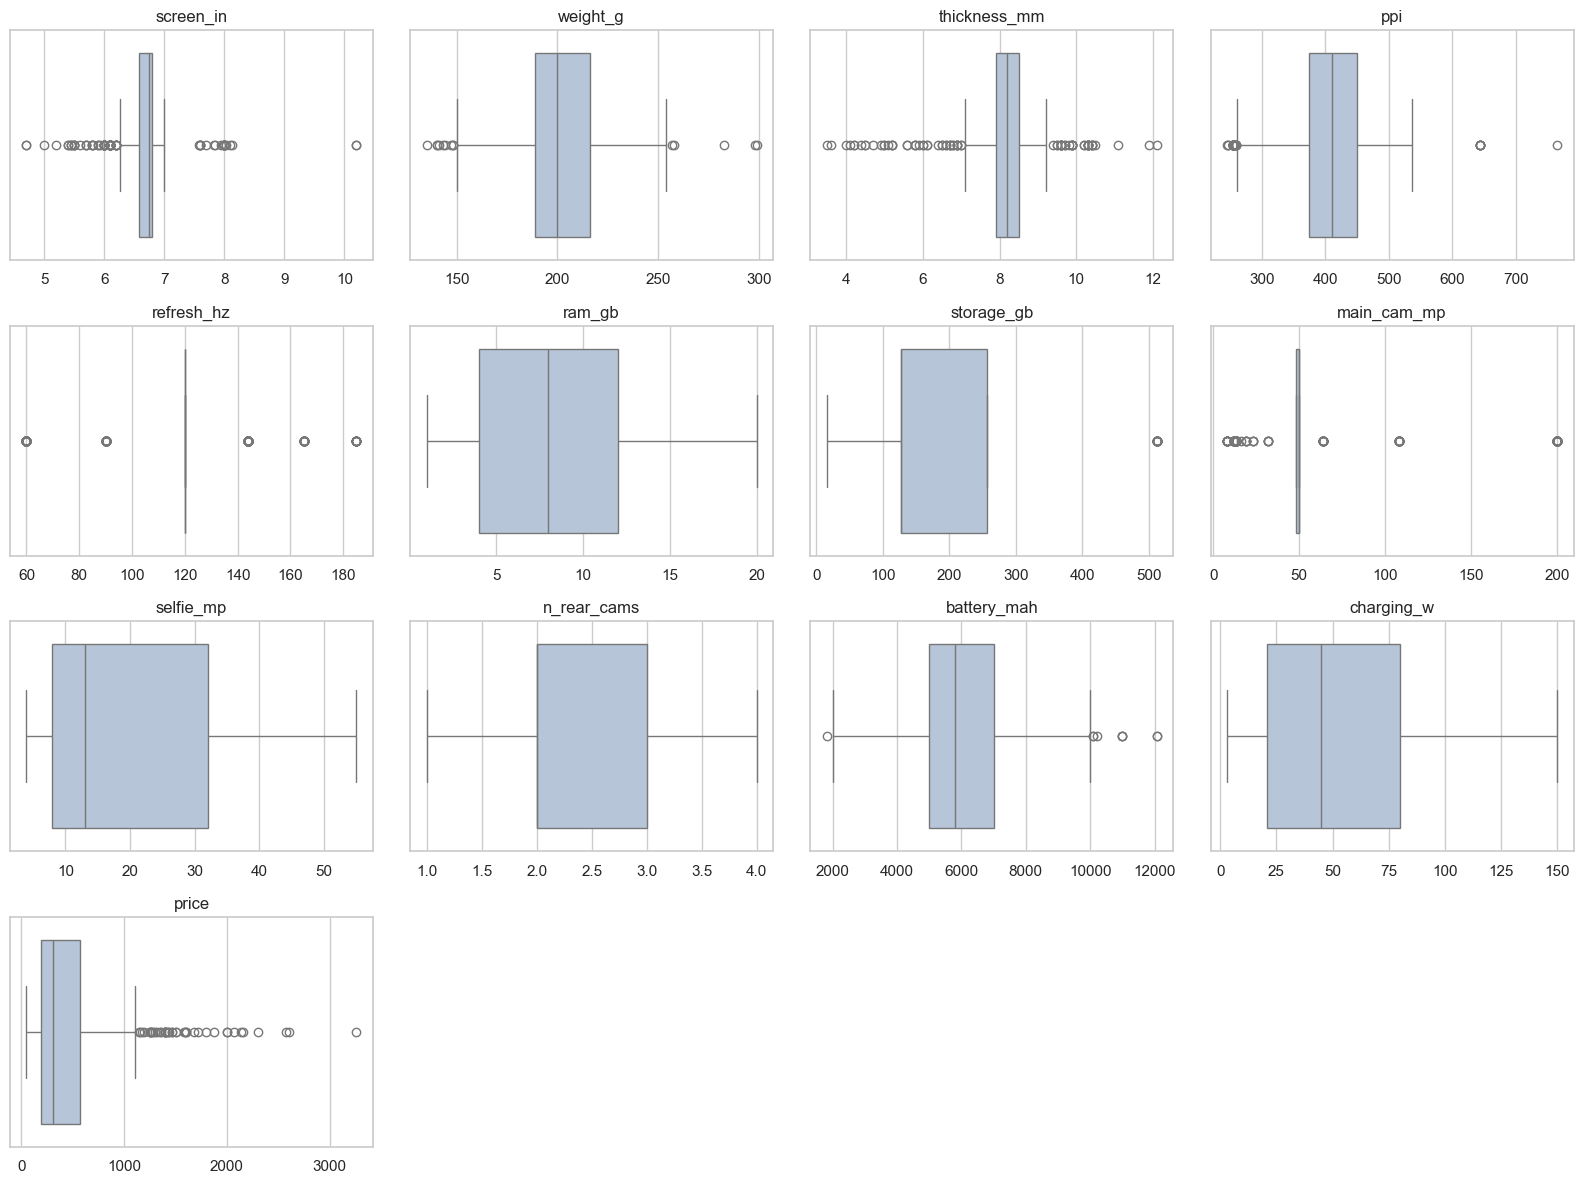

In [13]:
# [C13] Boxplots of every column
n = len(OUT_COLS); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3 * nrow))
for ax, c in zip(axes.ravel(), OUT_COLS):
    sns.boxplot(x=df[c], ax=ax, color="lightsteelblue"); ax.set_title(c); ax.set_xlabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); save("outlier_boxplots"); plt.show()

### Outlier treatment
Every phone flagged by both methods was checked by name. All are real products: small phones (iPhone SE/mini), foldables and the tri-fold Mate XT (screen and thickness measured unfolded), the chunky Xperia XZ2 family, and Honor's 10,000+ mAh phones. None is an error, so **no rows are removed**.

PCA is variance-based, so a few extreme values could dominate a component. Rule applied: a value is treated only if **both** methods flag it, and it is **winsorised** to the most extreme value among the non-flagged phones. This keeps all rows and the order of phones, and only shortens the extreme tips.
* `refresh_hz` and `main_cam_mp` are skipped: they take a few discrete values (e.g. 90/120/144 Hz), so the IQR rule flags 40% and 37% of phones while Z-score flags none.
* **`price` treatment:** No price value was flagged by both the IQR and Z-score methods. However, the extreme right tail was handled separately by winsorising prices above the **99th percentile (€2,030.8)**, affecting **7 phones**. This cap is used for exploratory analysis and clustering; regression uses the **original, uncapped price values** from the pre-treatment snapshot (`df_unimputed`).


In [14]:
# [C14] Outlier treatment: winsorise values flagged by BOTH methods + extreme price tail
SKIP = ["refresh_hz", "main_cam_mp", "price"]   # discrete specs skipped; price handled via 99th pct cap below
before = df[OUT_COLS].copy()
log = []
for c in OUT_COLS:
    if c in SKIP:
        continue
    iqr_flag, z_flag, lo, hi = flags[c]
    confirmed = iqr_flag & z_flag
    if confirmed.sum() == 0:
        continue
    normal = df.loc[~confirmed, c]
    low_cap, high_cap = normal.min(), normal.max()
    df[c] = df[c].clip(low_cap, high_cap)
    log.append({"column": c, "values capped": int(confirmed.sum()),
                "range before": f"{before[c].min():,.1f} to {before[c].max():,.1f}",
                "range after": f"{df[c].min():,.1f} to {df[c].max():,.1f}"})

# Cap extreme right-tail price outliers (above 99th percentile, e.g., ROG Phone 8 at 3260 EUR)
p99 = df["price"].quantile(0.99)
price_capped = (df["price"] > p99).sum()
if price_capped > 0:
    df["price"] = df["price"].clip(upper=p99)
    log.append({"column": "price", "values capped": int(price_capped),
                "range before": f"{before['price'].min():,.1f} to {before['price'].max():,.1f}",
                "range after": f"{df['price'].min():,.1f} to {df['price'].max():,.1f}"})

print(pd.DataFrame(log).to_string(index=False))
changed = (before != df[OUT_COLS]).any(axis=1)
print("\nphones with at least one value capped:", int(changed.sum()), "of", len(df))
print("rows removed: 0 | rows now:", len(df))

df.to_csv("../data/gsmarena_phones_clean.csv", index=False)
print("saved ../data/gsmarena_phones_clean.csv")


      column  values capped        range before         range after
   screen_in             18         4.7 to 10.2          5.6 to 8.0
    weight_g              4      135.0 to 299.0      140.0 to 258.0
thickness_mm             20         3.5 to 12.1         5.6 to 10.5
         ppi              1      245.0 to 765.0      245.0 to 643.0
 battery_mah              5 1,821.0 to 12,070.0 1,821.0 to 10,200.0
       price              7     50.0 to 3,260.0     50.0 to 2,030.8

phones with at least one value capped: 41 of 657
rows removed: 0 | rows now: 657
saved ../data/gsmarena_phones_clean.csv


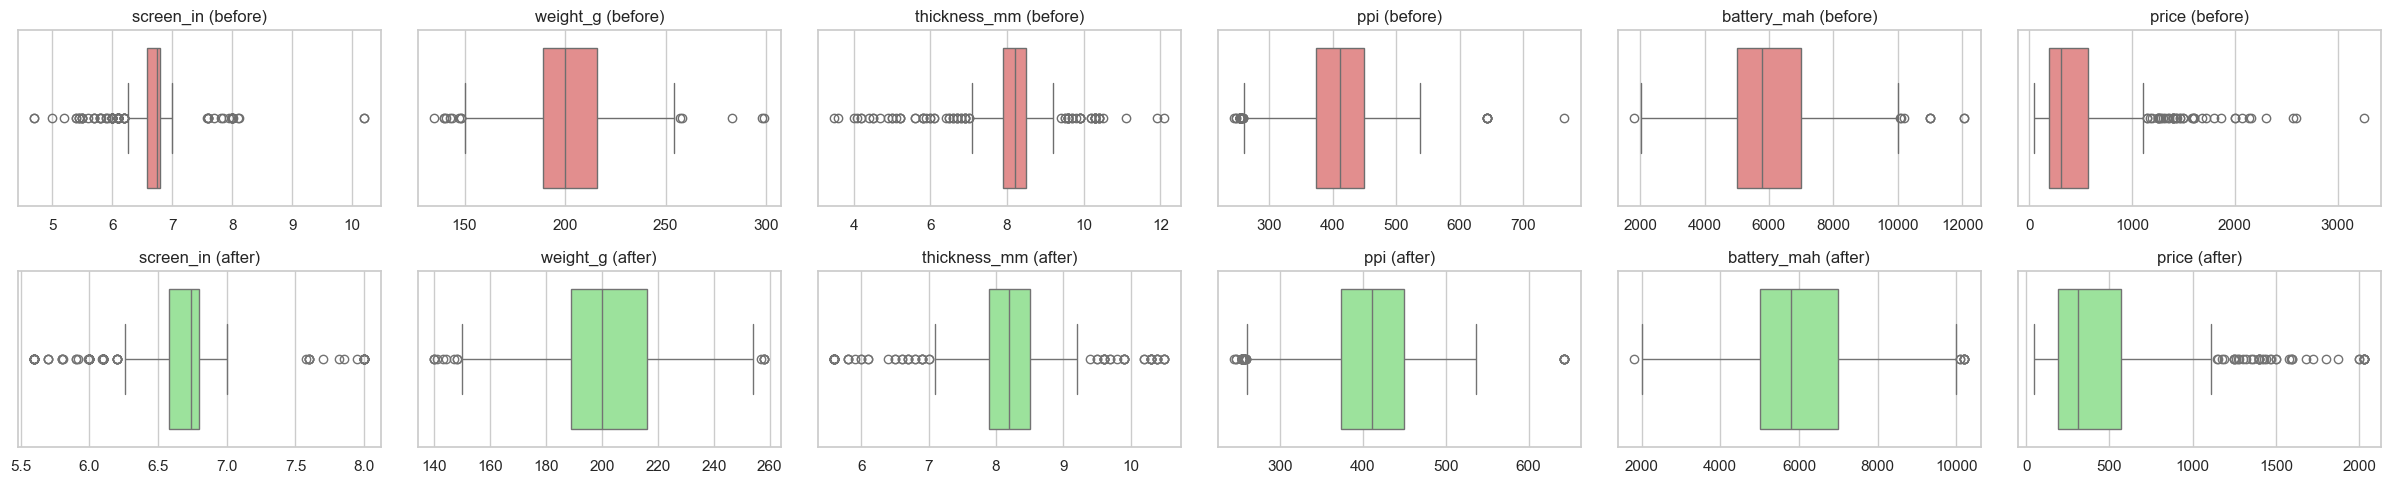

In [15]:
# [C15] Before / after boxplots for the columns that were treated
changed_cols = [r["column"] for r in log]
fig, axes = plt.subplots(2, len(changed_cols), figsize=(4 * len(changed_cols), 5), squeeze=False)
for j, c in enumerate(changed_cols):
    sns.boxplot(x=before[c], ax=axes[0, j], color="lightcoral"); axes[0, j].set_title(f"{c} (before)")
    sns.boxplot(x=df[c], ax=axes[1, j], color="lightgreen");     axes[1, j].set_title(f"{c} (after)")
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("")
plt.tight_layout(); save("outlier_before_after"); plt.show()

## 5. (b) PCA
PCA finds new axes (components) that capture as much of the variation in the specs as possible. It follows variance, so a column in large units (battery in mAh) would dominate one in small units (screen in inches). We therefore **standardise** first: every column gets mean 0 and standard deviation 1.

The number of components is chosen from the explained variance with two rules: **Kaiser** (keep components with eigenvalue > 1, i.e. more variance than a single original column) and **cumulative variance** (keep enough components for 85%). The scree plot shows where the curve flattens:
* **Kaiser rule (`eigenvalue > 1`):** Retains **4 components**, explaining **77.25%** of total variance (**PC1 = 41.37%**, **PC2 = 15.99%**, **PC3 = 10.88%**, **PC4 = 8.99%**).
* **85% cumulative variance rule:** Retains **6 components**, explaining **86.75%** of total variance.
* **Decision:** We keep **6 components** (`N_COMP = 6`) so clustering retains **>85% of the original hardware information** while cutting dimensionality in half.

after standardising: mean range -0.0 to -0.0 | std range 1.0 to 1.0


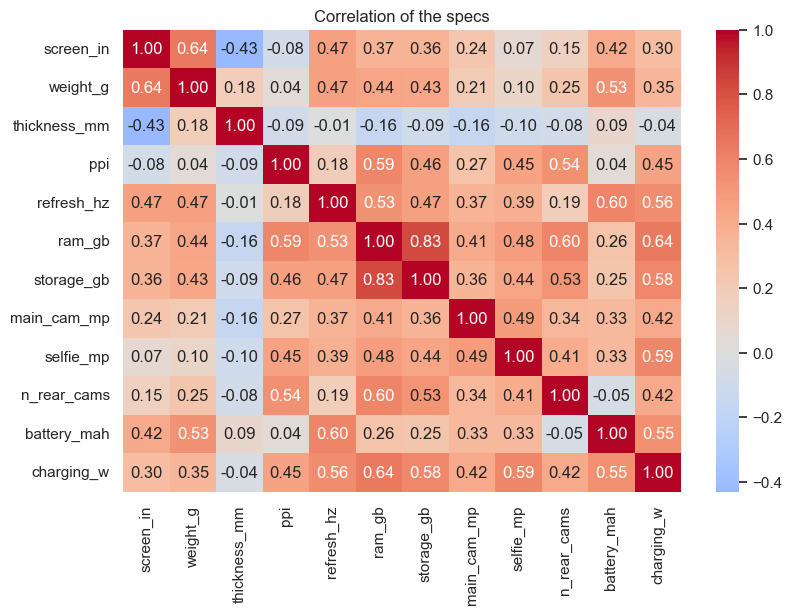

      eigenvalue  variance %  cumulative %
PC1         4.97       41.37         41.37
PC2         1.92       15.99         57.37
PC3         1.31       10.88         68.25
PC4         1.08        8.99         77.25
PC5         0.67        5.57         82.81
PC6         0.47        3.93         86.75
PC7         0.43        3.57         90.32
PC8         0.38        3.15         93.47
PC9         0.33        2.78         96.25
PC10        0.21        1.73         97.98
PC11        0.14        1.20         99.18
PC12        0.10        0.82        100.00

Kaiser rule (eigenvalue > 1): 4 components | 85% variance rule: 6 components


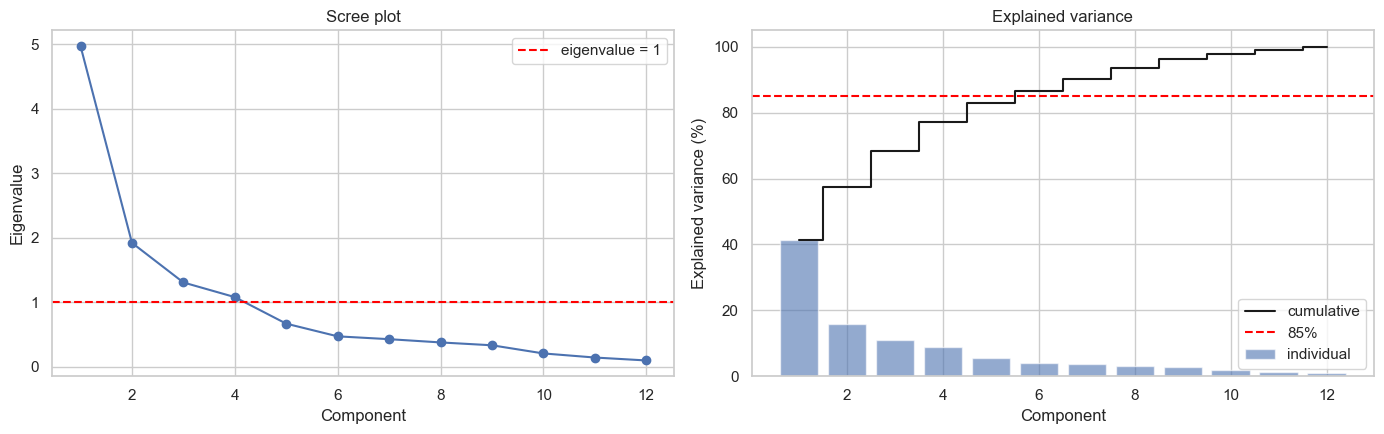

components kept: 6


In [16]:
# [C16] Standardise, then PCA: explained variance and scree plot
from sklearn.decomposition import PCA

X = df[FEATURES]
Xs = StandardScaler().fit_transform(X)                 # every column: mean 0, std 1
print("after standardising: mean range", Xs.mean(axis=0).round(2).min(), "to", Xs.mean(axis=0).round(2).max(),
      "| std range", Xs.std(axis=0).round(2).min(), "to", Xs.std(axis=0).round(2).max())

plt.figure(figsize=(9, 6))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of the specs"); save("correlation_heatmap"); plt.show()

pca_full = PCA().fit(Xs)
eig = pca_full.explained_variance_
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n_kaiser = int((eig > 1).sum())
n_85 = int(np.argmax(cum >= 0.85) + 1)
print(pd.DataFrame({"eigenvalue": eig, "variance %": evr * 100, "cumulative %": cum * 100},
                   index=[f"PC{i+1}" for i in range(len(eig))]).round(2))
print(f"\nKaiser rule (eigenvalue > 1): {n_kaiser} components | 85% variance rule: {n_85} components")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(range(1, len(eig) + 1), eig, "o-"); ax[0].axhline(1, color="red", ls="--", label="eigenvalue = 1")
ax[0].set_xlabel("Component"); ax[0].set_ylabel("Eigenvalue"); ax[0].set_title("Scree plot"); ax[0].legend()
ax[1].bar(range(1, len(evr) + 1), evr * 100, alpha=0.6, label="individual")
ax[1].step(range(1, len(evr) + 1), cum * 100, where="mid", color="k", label="cumulative")
ax[1].axhline(85, color="red", ls="--", label="85%")
ax[1].set_xlabel("Component"); ax[1].set_ylabel("Explained variance (%)"); ax[1].set_title("Explained variance"); ax[1].legend()
plt.tight_layout(); save("scree_plot"); plt.show()

N_COMP = n_85         
print("components kept:", N_COMP)

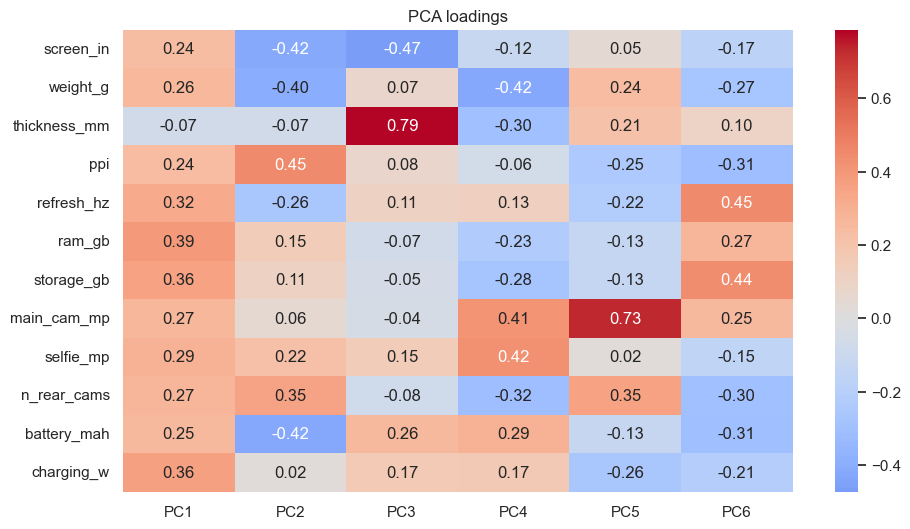

PC1 -> ram_gb (+0.39), charging_w (+0.36), storage_gb (+0.36), refresh_hz (+0.32)
PC2 -> ppi (+0.45), battery_mah (-0.42), screen_in (-0.42), weight_g (-0.40)
PC3 -> thickness_mm (+0.79), screen_in (-0.47), battery_mah (+0.26), charging_w (+0.17)
PC4 -> selfie_mp (+0.42), weight_g (-0.42), main_cam_mp (+0.41), n_rear_cams (-0.32)
PC5 -> main_cam_mp (+0.73), n_rear_cams (+0.35), charging_w (-0.26), ppi (-0.25)
PC6 -> refresh_hz (+0.45), storage_gb (+0.44), ppi (-0.31), battery_mah (-0.31)


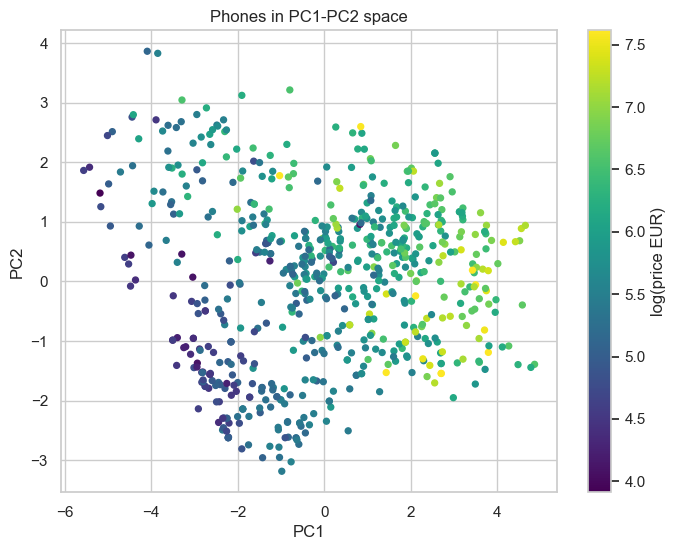

In [17]:
# [C17] Loadings: what each component means
pca = PCA(n_components=N_COMP).fit(Xs)
scores = pca.transform(Xs)
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=[f"PC{i+1}" for i in range(N_COMP)])

plt.figure(figsize=(1.3 * N_COMP + 3, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings"); save("pca_loadings"); plt.show()

for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, "->", ", ".join(f"{t} ({loadings.loc[t, pc]:+.2f})" for t in top))

plt.figure(figsize=(8, 6))
sc = plt.scatter(scores[:, 0], scores[:, 1], c=np.log(df["price"]), cmap="viridis", s=18)
plt.colorbar(sc, label="log(price EUR)"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Phones in PC1-PC2 space"); save("pca_scatter"); plt.show()

## 6. (c) K-Means clustering
We cluster on the PCA scores (the kept components): they are uncorrelated and leave out the noise in the weak components, so K-Means does not count correlated specs twice. K-Means needs `k` in advance, so two tools are used: the **elbow method** (inertia = squared distance of phones to their cluster centre; look for the `k` after which it stops dropping quickly) and the **silhouette score** (how well each phone fits its own cluster compared with the nearest other one, from -1 to 1; higher is better).

* **Choosing `k`:** Inertia drops steeply up to **`k = 4`** (**4,518.5 → 3,276.8**) before flattening, while the **silhouette score peaks at `k = 8` (0.301)** (with a secondary local peak at **`k = 4`, 0.289**). We select **`k = 8`** to capture fine-grained market sub-segments.

Clusters are numbered from `0` (lowest median price) upwards and described by their average specs, price, and brand mix:

The eight clusters reveal more specific smartphone market segments:

* **Cluster 0 – Entry-level budget:** 151 phones, median price €160, with approximately 4.7 GB RAM and 100 GB storage.
* **Cluster 1 – Older and lower-specification devices:** 71 phones, median price €230, approximately 4.3 GB RAM and a median release year of 2019.
* **Cluster 2 – Affordable midrange:** 86 phones, median price €274.50, approximately 8.3 GB RAM and 178.6 GB storage.
* **Cluster 3 – Mainstream 5G devices:** 95 phones, median price €321.50, with a strong presence of 5G-enabled models.
* **Cluster 4 – Performance-oriented mainstream devices:** 148 phones, median price €407.50, approximately 10.2 GB RAM, 229.2 GB storage and 87.4 W charging.
* **Cluster 5 – Camera-oriented premium devices:** 54 phones, median price €599.50, with particularly high average main and selfie camera megapixels.
* **Cluster 6 – High-end performance devices:** 31 phones, median price €1,036.80, approximately 14.8 GB RAM and 433.5 GB storage, with a substantial Asus presence.
* **Cluster 7 – Large-screen premium devices:** 21 phones, median price €1,400 and an average screen size of approximately 7.9 inches.

These labels represent the dominant characteristics of each cluster, not strict categories that apply to every phone. The cluster profiles should be interpreted using their average specifications, median prices and brand distributions.

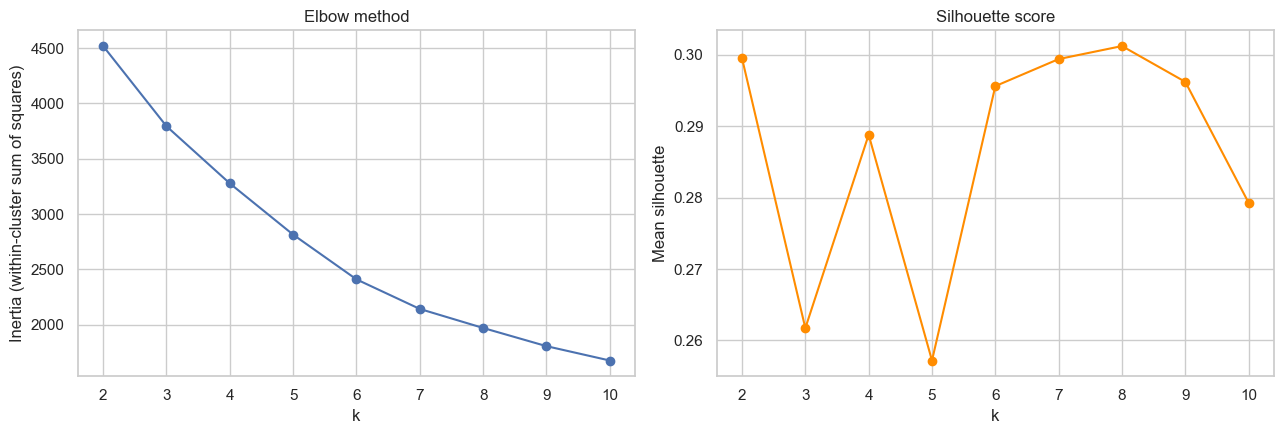

 k  inertia  silhouette
 2   4518.5       0.299
 3   3793.6       0.262
 4   3276.8       0.289
 5   2813.6       0.257
 6   2409.4       0.296
 7   2142.0       0.299
 8   1970.1       0.301
 9   1805.7       0.296
10   1675.8       0.279

k with the best silhouette: 8


In [18]:
# [C18] K-Means: choose k with the elbow method and the silhouette score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Z = scores                                   
ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia (within-cluster sum of squares)")
ax[1].plot(ks, sil, "o-", color="darkorange"); ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Mean silhouette")
plt.tight_layout(); save("kmeans_elbow_silhouette"); plt.show()
print(pd.DataFrame({"k": ks, "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)}).to_string(index=False))

K = ks[int(np.argmax(sil))]
print("\nk with the best silhouette:", K)

k = 8 | silhouette: 0.301
kmeans             0       1       2       3       4       5       6       7
n_phones       151.0    71.0    86.0    95.0   148.0    54.0    31.0    21.0
screen_in        6.8     6.0     6.7     6.5     6.7     6.7     6.8     7.9
weight_g       205.4   171.9   184.0   199.7   209.0   210.4   233.5   236.9
thickness_mm     8.3     8.5     7.4     8.4     8.2     8.1     9.3     5.6
ppi            274.1   402.0   418.0   423.2   447.9   452.2   434.4   394.9
refresh_hz     112.8    63.0   126.1   106.9   131.6   136.6   139.9   117.1
ram_gb           4.7     4.3     8.3     7.5    10.2    11.3    14.8    13.3
storage_gb     100.0    72.8   178.6   148.2   229.2   246.5   433.5   292.6
main_cam_mp     37.5    17.2    63.6    49.2    51.1   198.3    49.2    92.3
selfie_mp        7.3     8.8    23.5    14.6    29.8    42.7    22.4    13.0
n_rear_cams      1.4     1.8     2.1     2.7     2.5     2.8     3.1     2.9
battery_mah   6309.3  3548.1  5487.1  4794.8  7148

C:\Users\NISCHAL SHARMA\AppData\Local\Temp\ipykernel_2888\3955672701.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="kmeans", y="price", data=df, palette="viridis", ax=ax[2])


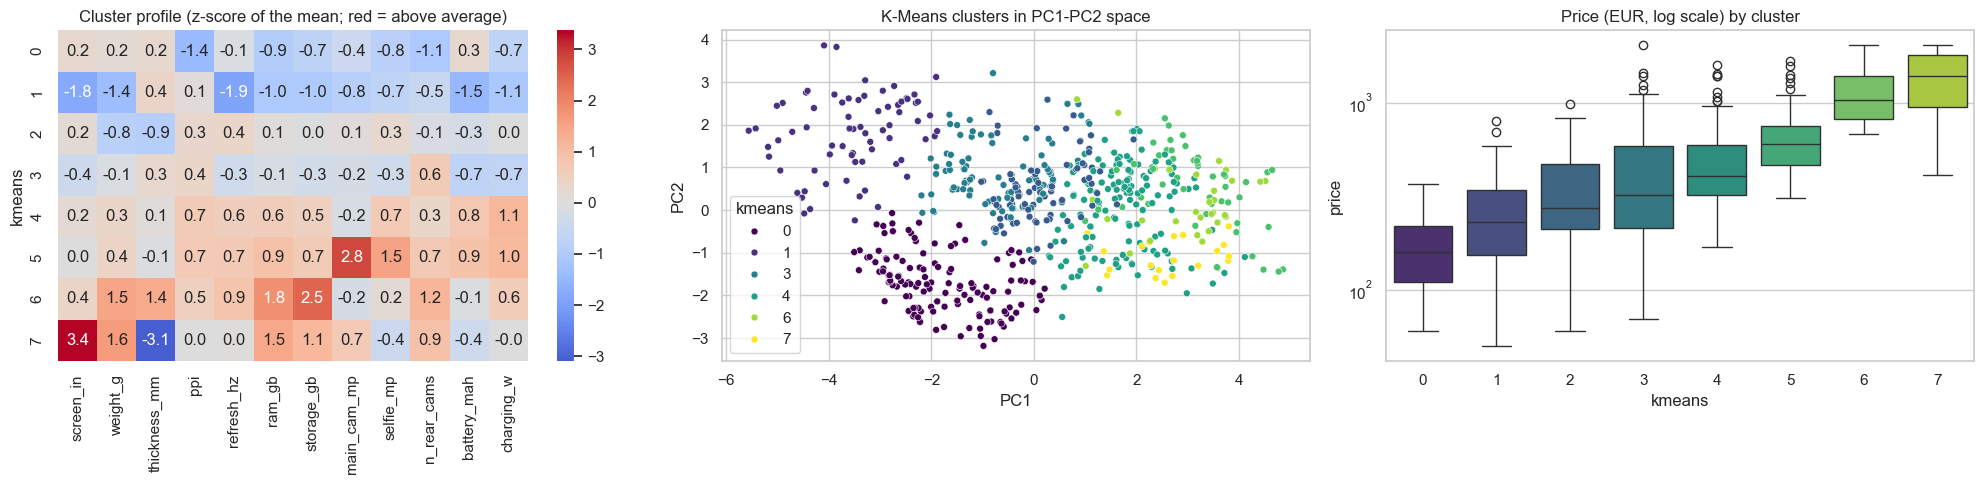

In [19]:
# [C19] Final K-Means and what each cluster represents
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Z)

def relabel_by_price(labels):
    """Number the clusters 0..k-1 from lowest to highest median price."""
    order = df.groupby(labels)["price"].median().sort_values().index
    return pd.Series(labels).map({old: new for new, old in enumerate(order)}).values

df["kmeans"] = relabel_by_price(km.labels_)
print("k =", K, "| silhouette:", round(silhouette_score(Z, df["kmeans"]), 3))

profile = df.groupby("kmeans")[FEATURES].mean()
profile.insert(0, "n_phones", df["kmeans"].value_counts().sort_index())
profile["median_price"] = df.groupby("kmeans")["price"].median()
profile["pct_5g"] = df.groupby("kmeans")["has_5g"].mean() * 100
profile["median_year"] = df.groupby("kmeans")["year"].median()
print(profile.round(1).T.to_string())

print("\ntop 3 brands in each cluster (share of the cluster):")
share = pd.crosstab(df["kmeans"], df["brand"], normalize="index") * 100
for k in share.index:
    print(f"  cluster {k}:", ", ".join(f"{b} {v:.0f}%" for b, v in share.loc[k].nlargest(3).items()))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
zprof = (profile[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
sns.heatmap(zprof, annot=True, fmt=".1f", cmap="coolwarm", center=0, ax=ax[0])
ax[0].set_title("Cluster profile (z-score of the mean; red = above average)")
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=df["kmeans"], palette="viridis", s=25, ax=ax[1])
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("K-Means clusters in PC1-PC2 space")
sns.boxplot(x="kmeans", y="price", data=df, palette="viridis", ax=ax[2])
ax[2].set_yscale("log"); ax[2].set_title("Price (EUR, log scale) by cluster")
plt.tight_layout(); save("kmeans_clusters"); plt.show()

## 7. (d) Agglomerative hierarchical clustering
Every phone starts as its own cluster and the two closest clusters are merged again and again, which produces a tree (dendrogram). **Ward linkage** merges the pair that increases the within-cluster variance least, the same goal K-Means has, which makes the two methods comparable; the cophenetic correlation of the other linkages is printed for reference. The tree is cut where the merge distance jumps the most (a big vertical gap means the next merge would join clusters that are far apart), shown by the red line.

* **Linkage & Cut:** Using **Ward linkage** (cophenetic correlation = **0.539**, chosen because it minimizes within-cluster variance just like K-Means), the largest merge-height jump occurs at **`k = 3` clusters** (**gap = 5.24**, cut at **height 35.07**), separating the market into three broad tiers: **Budget**, **Midrange**, and **Flagship**.
* **Comparison with K-Means:** Comparing Ward hierarchical clustering (k = 3) with K-Means (k = 8) gives an ARI of 0.331 and NMI of 0.461, indicating limited agreement between the two different segmentation granularities. When both algorithms use k = 8, agreement improves to ARI = 0.661 and NMI = 0.717. This suggests that the algorithms identify reasonably similar finer-grained groupings when the number of clusters is held constant, although their assignments are not identical.

cophenetic correlation (how well the tree keeps the real distances): {'ward': 0.539, 'average': 0.671, 'complete': 0.575, 'single': 0.554}
merge-height gap for k = 3..8: {3: 5.24, 4: 3.24, 5: 2.93, 6: 3.83, 7: 1.82, 8: 1.33}
cut -> 3 clusters, at height 35.07


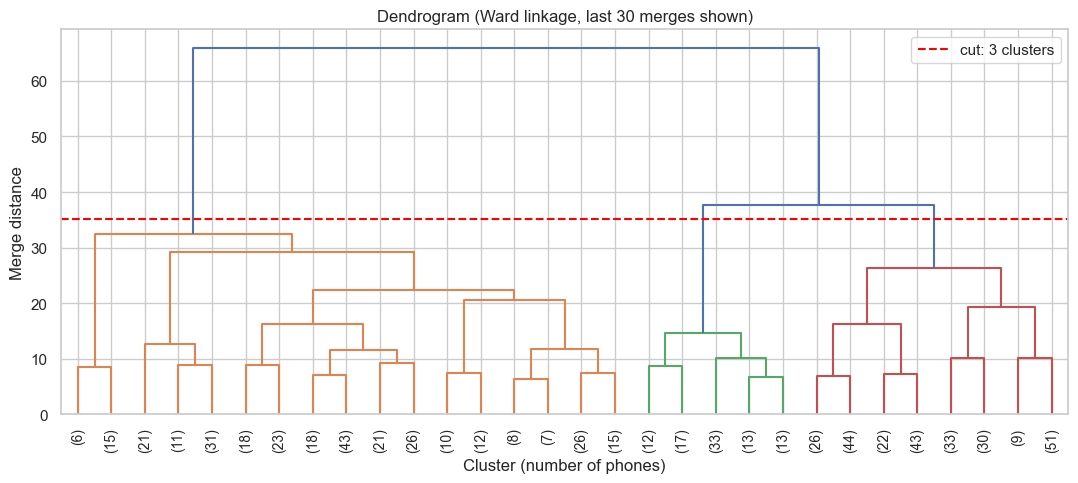

In [20]:
# [C20] Hierarchical clustering: linkage choice, dendrogram, where to cut
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

dist = pdist(Z)
coph = {m: cophenet(linkage(Z, m), dist)[0] for m in ["ward", "average", "complete", "single"]}
print("cophenetic correlation (how well the tree keeps the real distances):",
      {m: round(float(v), 3) for m, v in coph.items()})

Lw = linkage(Z, method="ward")
heights = Lw[:, 2]
# gap between the merge that creates k clusters and the next merge: a big gap = a natural place to cut
gaps = {k: heights[-(k - 1)] - heights[-k] for k in range(3, 9)}
print("merge-height gap for k = 3..8:", {k: round(float(v), 2) for k, v in gaps.items()})
K_H = max(gaps, key=gaps.get)
# K_H = 4        # uncomment and change if you prefer another number of clusters
cut_height = (heights[-(K_H - 1)] + heights[-K_H]) / 2
print("cut ->", K_H, "clusters, at height", round(float(cut_height), 2))

plt.figure(figsize=(13, 5))
dendrogram(Lw, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, color_threshold=cut_height)
plt.axhline(cut_height, color="red", ls="--", label=f"cut: {K_H} clusters")
plt.title("Dendrogram (Ward linkage, last 30 merges shown)")
plt.xlabel("Cluster (number of phones)"); plt.ylabel("Merge distance"); plt.legend()
save("dendrogram"); plt.show()

silhouette: hierarchical (k=3) 0.248 | K-Means (k=8) 0.301
agreement, hierarchical cut at k=3: ARI=0.331, NMI=0.461
agreement, hierarchical cut at the same k=8: ARI=0.661, NMI=0.717


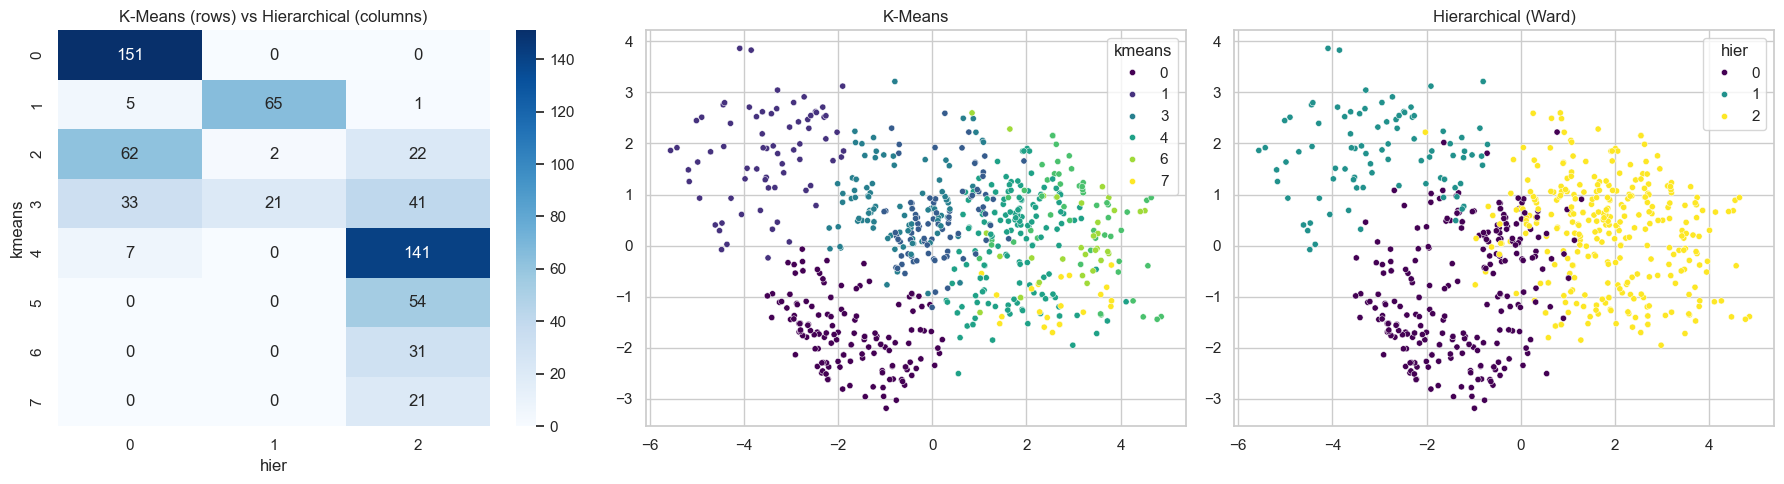

hier               0       1       2
n_phones       258.0    88.0   311.0
screen_in        6.7     6.0     6.8
weight_g       199.3   172.8   211.8
thickness_mm     8.1     8.4     8.1
ppi            328.1   414.2   442.0
refresh_hz     112.8    76.3   129.7
ram_gb           5.6     5.3    10.9
storage_gb     120.1    91.5   249.2
main_cam_mp     44.0    23.2    81.5
selfie_mp       11.1     9.6    29.3
n_rear_cams      1.7     1.9     2.7
battery_mah   5970.3  3690.5  6458.3
charging_w      34.1    18.0    73.9
median_price   190.0   261.9   531.0


In [21]:
# [C21] Compare hierarchical clusters with K-Means
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

df["hier"] = relabel_by_price(fcluster(Lw, K_H, criterion="maxclust"))
hier_same_k = relabel_by_price(fcluster(Lw, K, criterion="maxclust"))

print(f"silhouette: hierarchical (k={K_H}) {silhouette_score(Z, df['hier']):.3f} | K-Means (k={K}) {silhouette_score(Z, df['kmeans']):.3f}")
print(f"agreement, hierarchical cut at k={K_H}: ARI={adjusted_rand_score(df['kmeans'], df['hier']):.3f}, NMI={normalized_mutual_info_score(df['kmeans'], df['hier']):.3f}")
print(f"agreement, hierarchical cut at the same k={K}: ARI={adjusted_rand_score(df['kmeans'], hier_same_k):.3f}, NMI={normalized_mutual_info_score(df['kmeans'], hier_same_k):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(pd.crosstab(df["kmeans"], df["hier"]), annot=True, fmt="d", cmap="Blues", ax=ax[0])
ax[0].set_title("K-Means (rows) vs Hierarchical (columns)")
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=df["kmeans"], palette="viridis", s=20, ax=ax[1]); ax[1].set_title("K-Means")
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=df["hier"], palette="viridis", s=20, ax=ax[2]); ax[2].set_title("Hierarchical (Ward)")
plt.tight_layout(); save("kmeans_vs_hierarchical"); plt.show()

hprof = df.groupby("hier")[FEATURES].mean()
hprof.insert(0, "n_phones", df["hier"].value_counts().sort_index())
hprof["median_price"] = df.groupby("hier")["price"].median()
print(hprof.round(1).T.to_string())

## 8. (e) Linear regression
**Target:** `price` (EUR, continuous). **Predictors:** the 12 specs, release `year`, extracted `chip_nm`, and 8 binary/domain features (`has_5g`, `has_nfc`, `is_oled`, `has_card_slot`, `is_foldable`, `is_pro_ultra`, `is_flagship_chip`, `is_discontinued`). To prevent data leakage, regression reverts to the pre-imputation snapshot (`df_unimputed`), splits 80/20 **before** any statistical transformations (`random_state = 42`), computes outlier caps strictly from the training split, and fits `StandardScaler` and `KNNImputer` inside each cross-validation fold. Price stays in euros so RMSE and MAE can be read directly. We report R² (share of price variance explained), RMSE (typical error, punishes big misses), and MAE (average absolute error) on train and test, plus 5-fold cross-validation.

* **Baseline (`specs + engineered tiers`):** Achieved **train R² = 0.668** (RMSE **219.51 EUR**, MAE **139.78 EUR**) and **test R² = 0.587** (RMSE **238.50 EUR**, MAE **158.27 EUR**), with **5-fold CV R² = 0.623 ± 0.083**. Engineering domain features (`is_foldable`, `is_flagship_chip`, `chip_nm`, `is_pro_ultra`, `is_discontinued`) raised specs-only test R² substantially over raw specs alone (**0.430 → 0.587**).
* **Diagnostics & Multicollinearity:** Residual plots show right-skewed errors on high-end devices, and **VIF values** confirm expected collinearity among physically coupled specs (`screen_in`, `weight_g`, `ppi`).
* **`log(price)` & Ridge Improvement:** Predicting **`log(price)`** addresses the strong right-skew in phone prices (train mean **434 EUR**, median **310 EUR**). Adding one-hot **`brand` + `log(price)` + Ridge regularisation** achieved the strongest generalization: **CV R² = 0.708**, **CV MAE = 117.65 EUR**, and **test MAE = 136.19 EUR** (~44% of the median price), while raw `+ brand` reached **test R² = 0.670** (**RMSE = 213.25 EUR**).
* **Conclusion:** Hardware tiers and brand explain **~65–71% of price variance** under a strict leakage-free pipeline; the remaining **~29–35%** reflects factors absent from spec sheets (regional taxes, brand positioning) and GSMArena's rounded, mixed launch/secondary-market price estimates.


In [ ]:
# [C22] Linear regression (strictly leakage-free): split FIRST, fit preprocessing inside CV folds
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Split the un-imputed, un-treated snapshot FIRST
train_df, test_df = train_test_split(df_unimputed, test_size=0.2, random_state=RANDOM_STATE)
train_df, test_df = train_df.copy(), test_df.copy()

# 2. Keep original uncapped prices and predictor values for regression
y_tr = train_df["price"].copy()
y_te = test_df["price"].copy()

# 3. Leakage-free preprocessing pipeline (Scaler -> KNNImputer inside every CV fold)
num_cols_base = FEATURES + ["year", "chip_nm"]
pre_base = ColumnTransformer([
    ("num", make_pipeline(StandardScaler(), KNNImputer(n_neighbors=5)), num_cols_base),
    ("bin", "passthrough", BINARY)
])

REG_FEATURES = num_cols_base + BINARY
X_tr, X_te = train_df[REG_FEATURES], test_df[REG_FEATURES]
print("train:", X_tr.shape, "| test:", X_te.shape)

model = make_pipeline(pre_base, LinearRegression()).fit(X_tr, y_tr)

def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE (EUR)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE (EUR)": mean_absolute_error(y_true, y_pred)}

pred = model.predict(X_te)
res = pd.DataFrame({"train": metrics(y_tr, model.predict(X_tr)), "test": metrics(y_te, pred)}).T
print(res.round(3))

cv = cross_val_score(make_pipeline(pre_base, LinearRegression()), X_tr, y_tr, cv=5, scoring="r2")
print("\n5-fold cross-validated R2 (leakage-free): mean %.3f, std %.3f" % (cv.mean(), cv.std()))
print("for scale: train average price %.0f EUR, median %.0f EUR" % (y_tr.mean(), y_tr.median()))

train: (525, 22) | test: (132, 22)
          R2  RMSE (EUR)  MAE (EUR)
train  0.668     219.510    139.779
test   0.587     238.502    158.270

5-fold cross-validated R2 (leakage-free): mean 0.623, std 0.083
for scale: train average price 434 EUR, median 310 EUR


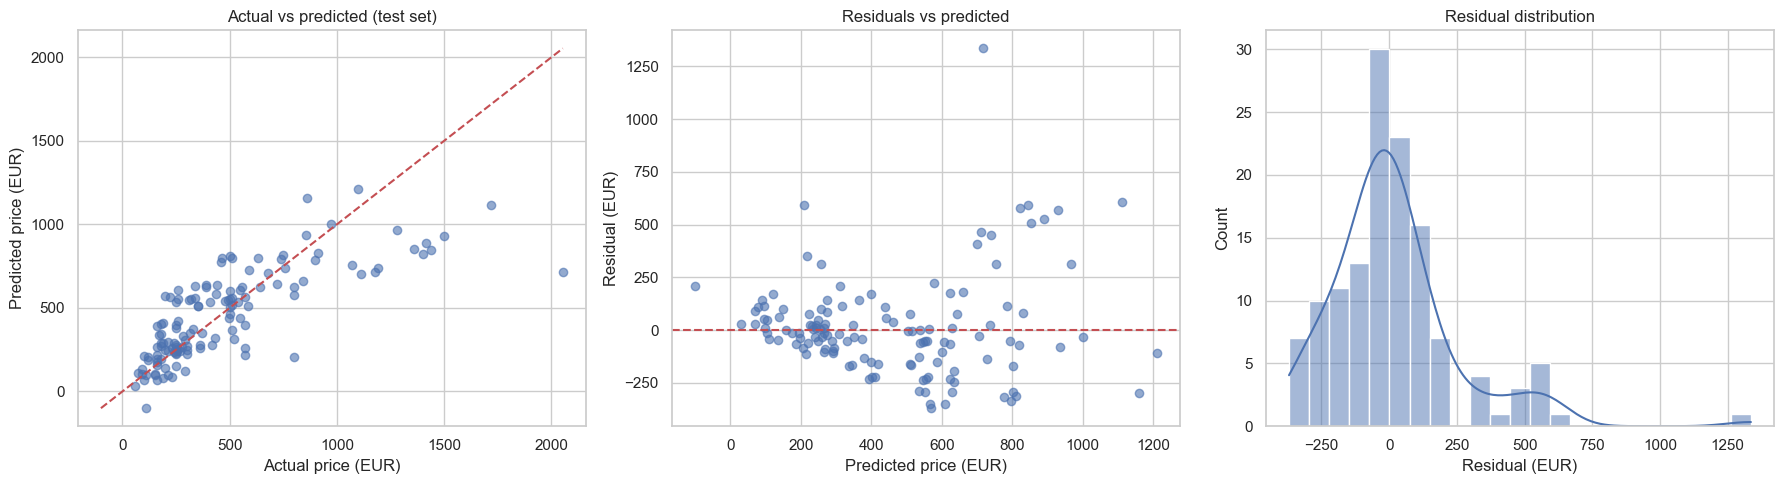

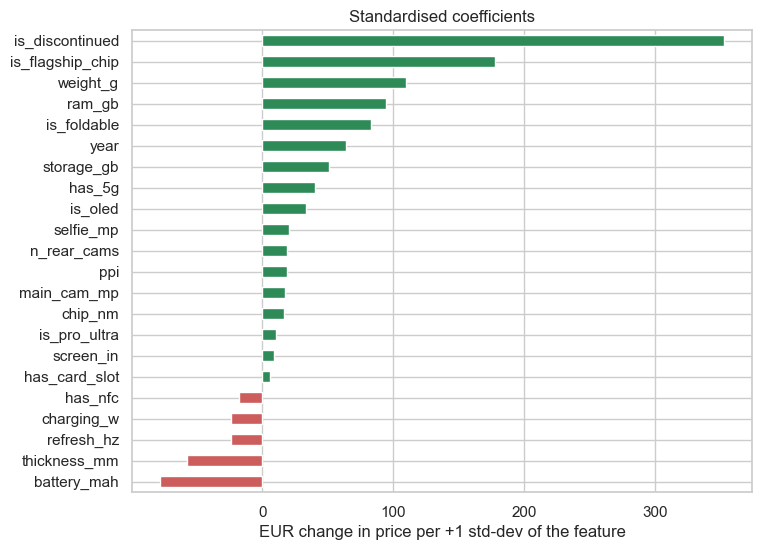

VIF:
ram_gb              7.16
screen_in           6.83
weight_g            5.84
ppi                 4.73
year                4.55
is_oled             4.51
thickness_mm        4.00
battery_mah         3.95
storage_gb          3.51
chip_nm             3.37
charging_w          3.02
refresh_hz          2.81
is_flagship_chip    2.50
n_rear_cams         2.49
has_5g              2.41
has_card_slot       2.37
selfie_mp           2.21
is_discontinued     2.16
has_nfc             1.96
is_foldable         1.81
main_cam_mp         1.62
is_pro_ultra        1.42


In [23]:
# [C23] Residual diagnostics, coefficients, multicollinearity
resid = y_te - pred
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(y_te, pred, alpha=0.6)
lim = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price (EUR)"); ax[0].set_ylabel("Predicted price (EUR)")
ax[0].set_title("Actual vs predicted (test set)")
ax[1].scatter(pred, resid, alpha=0.6); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted price (EUR)"); ax[1].set_ylabel("Residual (EUR)"); ax[1].set_title("Residuals vs predicted")
sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_xlabel("Residual (EUR)"); ax[2].set_title("Residual distribution")
plt.tight_layout(); save("regression_diagnostics"); plt.show()

coef = pd.Series(model.named_steps["linearregression"].coef_, index=REG_FEATURES).sort_values()
plt.figure(figsize=(8, 6))
coef.plot.barh(color=["indianred" if v < 0 else "seagreen" for v in coef])
plt.xlabel("EUR change in price per +1 std-dev of the feature"); plt.title("Standardised coefficients")
save("regression_coefficients"); plt.show()

# VIF: 1 / (1 - R2 of predicting this feature from all the others). Above ~5-10 = strong collinearity.
Xz = pre_base.fit_transform(X_tr)
vif = {}
for j, c in enumerate(REG_FEATURES):
    others = np.delete(Xz, j, axis=1)
    r2 = LinearRegression().fit(others, Xz[:, j]).score(others, Xz[:, j])
    vif[c] = 1 / (1 - r2)
print("VIF:"); print(pd.Series(vif).sort_values(ascending=False).round(2).to_string())

In [24]:
# [C24] Prices are right-skewed: also try predicting log(price)
m_log = make_pipeline(pre_base, LinearRegression()).fit(X_tr, np.log(y_tr))
pred_log = np.exp(m_log.predict(X_te))                       # back to EUR
compare = pd.DataFrame({"price": metrics(y_te, pred), "log(price), back to EUR": metrics(y_te, pred_log)}).T
print(compare.round(3))
print("\nR2 on the log scale (test):", round(r2_score(np.log(y_te), m_log.predict(X_te)), 3))

                            R2  RMSE (EUR)  MAE (EUR)
price                    0.587     238.502    158.270
log(price), back to EUR  0.583     239.458    143.689

R2 on the log scale (test): 0.724


In [25]:
# [C24b] Sensitivity: effect of the single biggest miss
pred_s = pd.Series(pred, index=y_te.index)
worst = resid.abs().idxmax()
print("worst phone:", df.loc[worst, "name"], "| actual:", round(float(y_te[worst])),
      "| predicted:", round(float(pred_s[worst])), "| error:", round(float(resid[worst])))
share = resid[worst] ** 2 / (resid ** 2).sum() * 100
print(f"this one phone makes up {share:.0f}% of the total squared error on the test set")
keep = y_te.index != worst
print("\ntest metrics WITHOUT that phone:")
print(pd.Series(metrics(y_te[keep], pred[keep])).round(3))

worst phone: ROG Phone 8 | actual: 2053 | predicted: 718 | error: 1336
this one phone makes up 24% of the total squared error on the test set

test metrics WITHOUT that phone:
R2              0.634
RMSE (EUR)    209.045
MAE (EUR)     149.282
dtype: float64


### Improving the regression
The baseline uses specs only. Price also depends on the brand (e.g. Apple vs Tecno), which is in the data but not in the model, so we add it as one-hot columns (still linear regression). We also try predicting log(price), and Ridge regression (a linear model that shrinks coefficients, useful when predictors are correlated). The models are compared with **5-fold cross-validation on the training set**, so the test set is used only once at the end and stays an honest estimate. 

We selected Ridge Regression with brand and log-transformed price because it achieved the best 5-fold cross-validation performance, with an R² of 0.706 and an MAE of approximately €117.67.

In [ ]:
# [C25] Can we do better? Add engineered tiers, brand, log(price), and Ridge (strictly leakage-free)
num_cols = FEATURES + ["year", "chip_nm"]

def make_pre(with_brand):
    parts = [
        ("num", make_pipeline(StandardScaler(), KNNImputer(n_neighbors=5)), num_cols),
        ("bin", "passthrough", BINARY)
    ]
    if with_brand:
        parts.append(("brand", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["brand"]))
    return ColumnTransformer(parts)

Xb_tr = train_df[num_cols + BINARY + ["brand"]]
Xb_te = test_df[num_cols + BINARY + ["brand"]]

models = {
    "1. specs + tiers (baseline)":      make_pipeline(make_pre(False), LinearRegression()),
    "2. + brand":                    make_pipeline(make_pre(True), LinearRegression()),
    "3. + brand, log(price)":        TransformedTargetRegressor(make_pipeline(make_pre(True), LinearRegression()),
                                                                func=np.log, inverse_func=np.exp),
    "4. + brand, log(price), Ridge": TransformedTargetRegressor(make_pipeline(make_pre(True), RidgeCV(alphas=np.logspace(-2, 3, 30))),
                                                                func=np.log, inverse_func=np.exp),
}
rows = []
for name, mdl in models.items():
    cv_r2 = cross_val_score(mdl, Xb_tr, y_tr, cv=5, scoring="r2")
    cv_mae = -cross_val_score(mdl, Xb_tr, y_tr, cv=5, scoring="neg_mean_absolute_error")
    mdl.fit(Xb_tr, y_tr)
    m = metrics(y_te, mdl.predict(Xb_te))
    rows.append({"model": name, "CV R2": cv_r2.mean(), "CV MAE": cv_mae.mean(),
                 "test R2": m["R2"], "test RMSE": m["RMSE (EUR)"], "test MAE": m["MAE (EUR)"]})
comparison = pd.DataFrame(rows).set_index("model")
print(comparison.round(3).to_string())


                               CV R2   CV MAE  test R2  test RMSE  test MAE
model                                                                      
1. specs + tiers (baseline)    0.628  144.785    0.587    238.486   158.771
2. + brand                     0.659  143.233    0.670    213.251   146.609
3. + brand, log(price)         0.705  118.392    0.653    218.485   135.780
4. + brand, log(price), Ridge  0.708  117.648    0.648    220.217   136.194


## Regression Conclusions

Under a strict leakage-free pipeline (splitting 80/20 before fitting outlier caps, scalers, and KNN imputation), engineering domain-specific hardware features—including `is_foldable`, `is_flagship_chip`, `chip_nm`, `is_pro_ultra`, and `is_discontinued`—improved the baseline model's test R² from **0.430** to **0.587**.

Adding one-hot encoded `brand` information further improved the test R² to **0.670** and reduced the test RMSE to **€213.25**.

Predicting log-transformed price improved cross-validation performance considerably. Among the four models, Ridge Regression with brand and log-transformed price achieved the best 5-fold cross-validation results, with **CV R² = 0.708** and **CV MAE = €117.65**.

However, the log-price model without Ridge achieved the lowest test MAE of **€135.78**, while the Ridge model achieved **€136.19**. The linear model with brand on raw price achieved the highest test R² of **0.670** and the lowest test RMSE of **€213.25**.

Therefore, Ridge was selected based on its superior cross-validation performance rather than claiming that it was the best model across every single test metric.

The remaining prediction errors reflect factors not fully represented by smartphone specifications, such as regional pricing, taxes, brand positioning, memory variants, and GSMArena's rounded, mixed launch and secondary-market estimates.


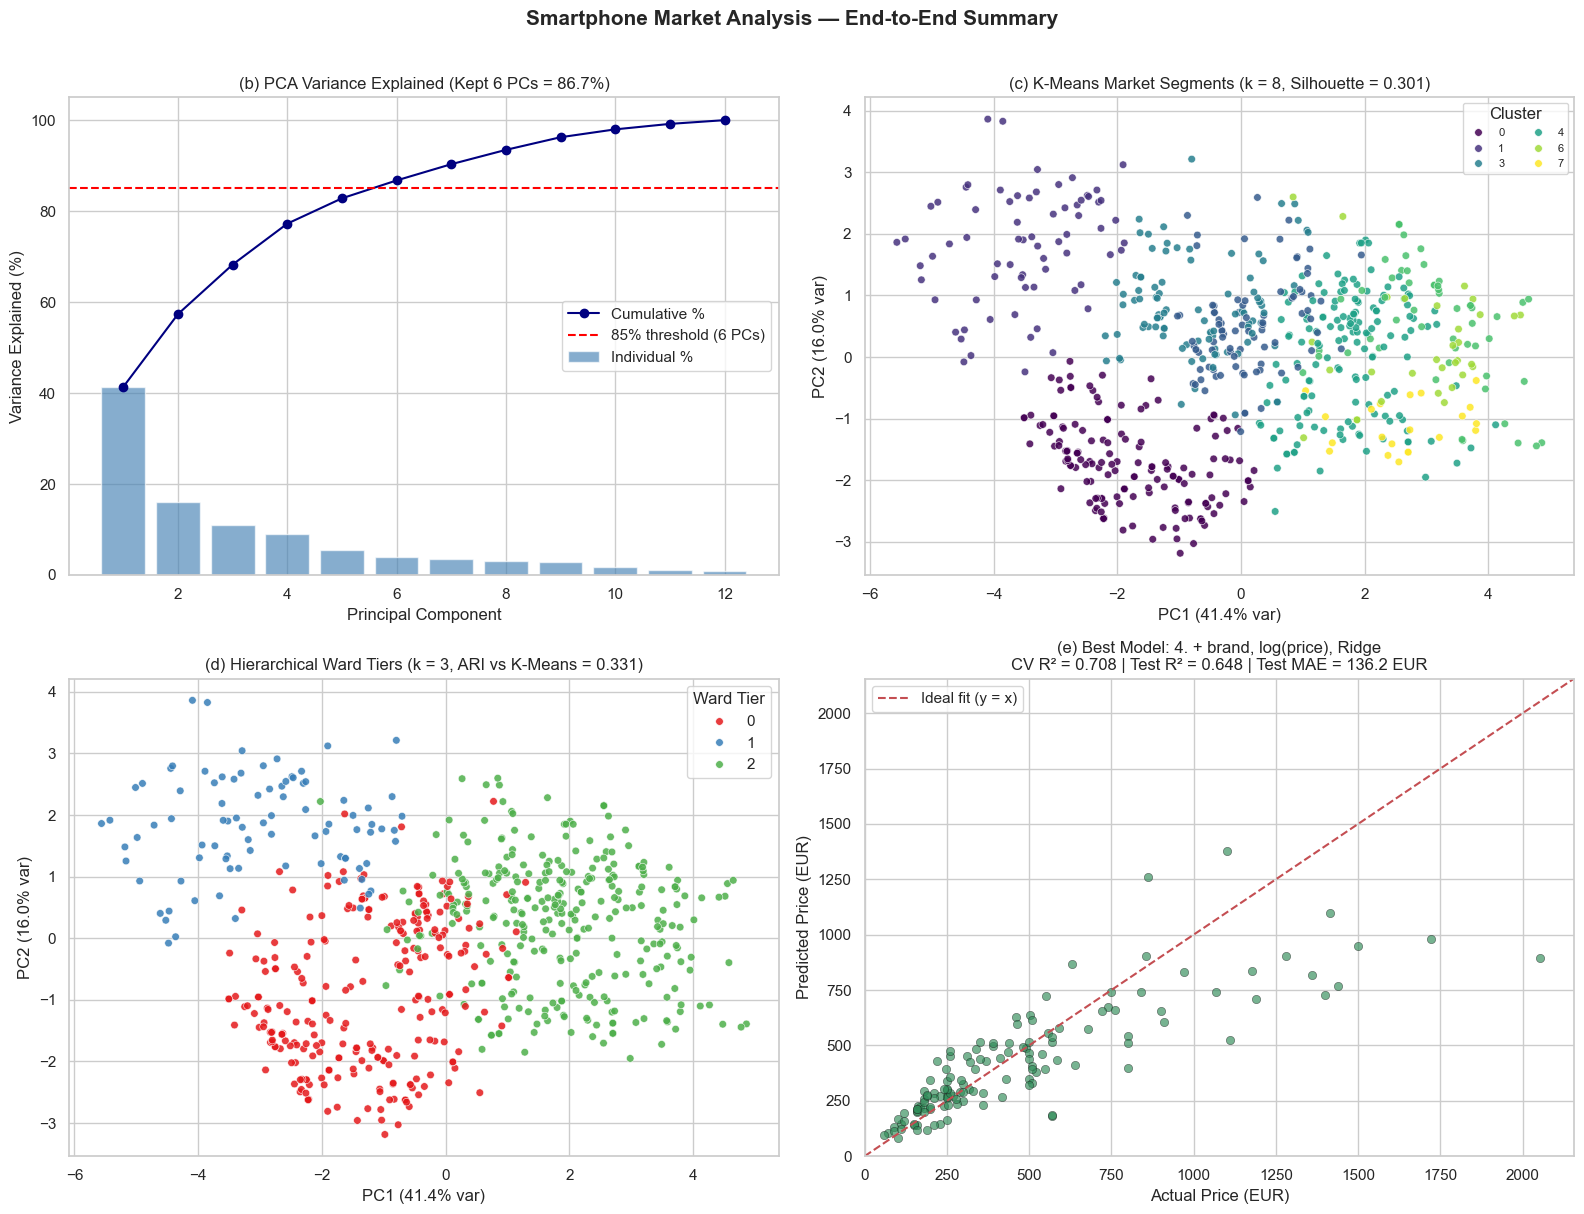

FINAL PROJECT SUMMARY
Dataset          : 657 modern smartphones (2018–2026) across 16 brands
Price Range      : Median 311 EUR | Mean 441 EUR (99th pct capped)
PCA              : 6 components kept -> 86.75% variance explained (Kaiser = 4 PCs)
K-Means          : k = 8 clusters | Silhouette = 0.301
Hierarchical     : k = 3 Ward tiers | Silhouette = 0.248 | ARI = 0.331
Best Regression  : 4. + brand, log(price), Ridge
                   CV R² = 0.708 | Test R² = 0.648 | Test RMSE = 220.22 EUR | Test MAE = 136.19 EUR


In [27]:
# [C26] Final Executive Summary: PCA + K-Means + Hierarchical + Linear Regression
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. PCA: Cumulative Explained Variance
ax = axes[0, 0]
ax.bar(range(1, len(evr) + 1), evr * 100, alpha=0.65, color="steelblue", label="Individual %")
ax.plot(range(1, len(cum) + 1), cum * 100, "o-", color="navy", label="Cumulative %")
ax.axhline(85, color="red", ls="--", label="85% threshold (6 PCs)")
ax.set_title(f"(b) PCA Variance Explained (Kept {N_COMP} PCs = {cum[N_COMP-1]*100:.1f}%)")
ax.set_xlabel("Principal Component"); ax.set_ylabel("Variance Explained (%)")
ax.legend(loc="center right")

# 2. K-Means Clusters in PC1-PC2 Space
ax = axes[0, 1]
sns.scatterplot(
    x=scores[:, 0], y=scores[:, 1], hue=df["kmeans"],
    palette="viridis", s=30, alpha=0.85, ax=ax
)
ax.set_title(f"(c) K-Means Market Segments (k = {K}, Silhouette = {silhouette_score(Z, df['kmeans']):.3f})")
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}% var)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}% var)")
ax.legend(title="Cluster", ncol=2, fontsize=8)

# 3. Hierarchical Clusters in PC1-PC2 Space
ax = axes[1, 0]
sns.scatterplot(
    x=scores[:, 0], y=scores[:, 1], hue=df["hier"],
    palette="Set1", s=30, alpha=0.85, ax=ax
)
ax.set_title(f"(d) Hierarchical Ward Tiers (k = {K_H}, ARI vs K-Means = {adjusted_rand_score(df['kmeans'], df['hier']):.3f})")
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}% var)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}% var)")
ax.legend(title="Ward Tier")

# 4. Best Regression Model: Actual vs Predicted Price (Test Set)
ax = axes[1, 1]
best_name = comparison["CV R2"].idxmax()
best_mdl = models[best_name]
best_pred = best_mdl.predict(Xb_te)
ax.scatter(y_te, best_pred, alpha=0.65, color="seagreen", edgecolors="k", linewidths=0.4)
lims = [0, max(y_te.max(), best_pred.max()) * 1.05]
ax.plot(lims, lims, "r--", lw=1.5, label="Ideal fit (y = x)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title(f"(e) Best Model: {best_name}\nCV R² = {comparison.loc[best_name, 'CV R2']:.3f} | Test R² = {comparison.loc[best_name, 'test R2']:.3f} | Test MAE = {comparison.loc[best_name, 'test MAE']:.1f} EUR")
ax.set_xlabel("Actual Price (EUR)"); ax.set_ylabel("Predicted Price (EUR)")
ax.legend()

plt.suptitle("Smartphone Market Analysis — End-to-End Summary", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
save("final_summary")
plt.show()

# Print concise numerical summary for report conclusions
print("=" * 68)
print("FINAL PROJECT SUMMARY")
print("=" * 68)
print(f"Dataset          : {len(df)} modern smartphones (2018–2026) across {df['brand'].nunique()} brands")
print(f"Price Range      : Median {df['price'].median():.0f} EUR | Mean {df['price'].mean():.0f} EUR (99th pct capped)")
print(f"PCA              : {N_COMP} components kept -> {cum[N_COMP-1]*100:.2f}% variance explained (Kaiser = {n_kaiser} PCs)")
print(f"K-Means          : k = {K} clusters | Silhouette = {silhouette_score(Z, df['kmeans']):.3f}")
print(f"Hierarchical     : k = {K_H} Ward tiers | Silhouette = {silhouette_score(Z, df['hier']):.3f} | ARI = {adjusted_rand_score(df['kmeans'], df['hier']):.3f}")
print(f"Best Regression  : {best_name}")
print(f"                   CV R² = {comparison.loc[best_name, 'CV R2']:.3f} | Test R² = {comparison.loc[best_name, 'test R2']:.3f} | Test RMSE = {comparison.loc[best_name, 'test RMSE']:.2f} EUR | Test MAE = {comparison.loc[best_name, 'test MAE']:.2f} EUR")
print("=" * 68)
